# Generate Plots -- Reliability-Aware RUL Prediction

Reads every `results/<method>__<scenario>.csv` file exported by the UQ notebooks
(each has columns `Engine_ID, Actual_RUL, Predicted_RUL, Uncertainty`) and builds:

1. Predicted vs. True RUL scatter -- per method/scenario
2. Uncertainty-band plot -- per method/scenario, sorted by true RUL
3. Risk-coverage curve -- all methods overlaid, per scenario (the headline abstention figure)
4. Method comparison bar chart -- RMSE / Score / Coverage at 100% and at 80% acceptance

Run this only after every UQ notebook you care about has had the export cell
added to its end and been re-run once.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "results"

def nasa_score(actual, predicted):
    d = np.asarray(predicted) - np.asarray(actual)
    s = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
    return np.sum(s)


In [2]:
import os
import glob
import pandas as pd

expected_files = {
    "mc_dropout__clean_capped.csv",
    "mc_dropout__missing_capped.csv",
    "deep_ensembles__clean_capped.csv",
    "deep_ensembles__missing_capped.csv",
    "conformal__clean_capped.csv",
    "conformal__missing_capped.csv",
    "mc_dropout__clean_uncapped.csv",
    "mc_dropout__missing_uncapped.csv",
    "deep_ensembles__clean_uncapped.csv",
    "deep_ensembles__missing_uncapped.csv",
    "conformal__clean_uncapped.csv",
    "conformal__missing_uncapped.csv",
}

actual_files = {
    os.path.basename(path)
    for path in glob.glob(os.path.join(RESULTS_DIR, "*.csv"))
}

print("CSV files found:", len(actual_files))

missing_files = expected_files - actual_files
extra_files = actual_files - expected_files

if missing_files:
    print("\nMissing expected files:")
    for f in sorted(missing_files):
        print(" -", f)

if extra_files:
    print("\nExtra CSV files:")
    for f in sorted(extra_files):
        print(" -", f)

if not missing_files:
    print("\nAll 12 expected CSV files are present.")

CSV files found: 12

All 12 expected CSV files are present.


## Load every exported results file

In [3]:
results = {}

for path in sorted(glob.glob(os.path.join(RESULTS_DIR, "*.csv"))):
    key = os.path.splitext(os.path.basename(path))[0]  # e.g. "mc_dropout__clean_capped"
    df = pd.read_csv(path)
    results[key] = df
    print(f"{key:40s} -> {len(df)} rows")

if not results:
    print("No files found in results/ -- add the export cell to your notebooks and rerun them first.")


conformal__clean_capped                  -> 100 rows
conformal__clean_uncapped                -> 100 rows
conformal__missing_capped                -> 100 rows
conformal__missing_uncapped              -> 100 rows
deep_ensembles__clean_capped             -> 100 rows
deep_ensembles__clean_uncapped           -> 100 rows
deep_ensembles__missing_capped           -> 100 rows
deep_ensembles__missing_uncapped         -> 100 rows
mc_dropout__clean_capped                 -> 100 rows
mc_dropout__clean_uncapped               -> 100 rows
mc_dropout__missing_capped               -> 100 rows
mc_dropout__missing_uncapped             -> 100 rows


## 1. Predicted vs. True RUL

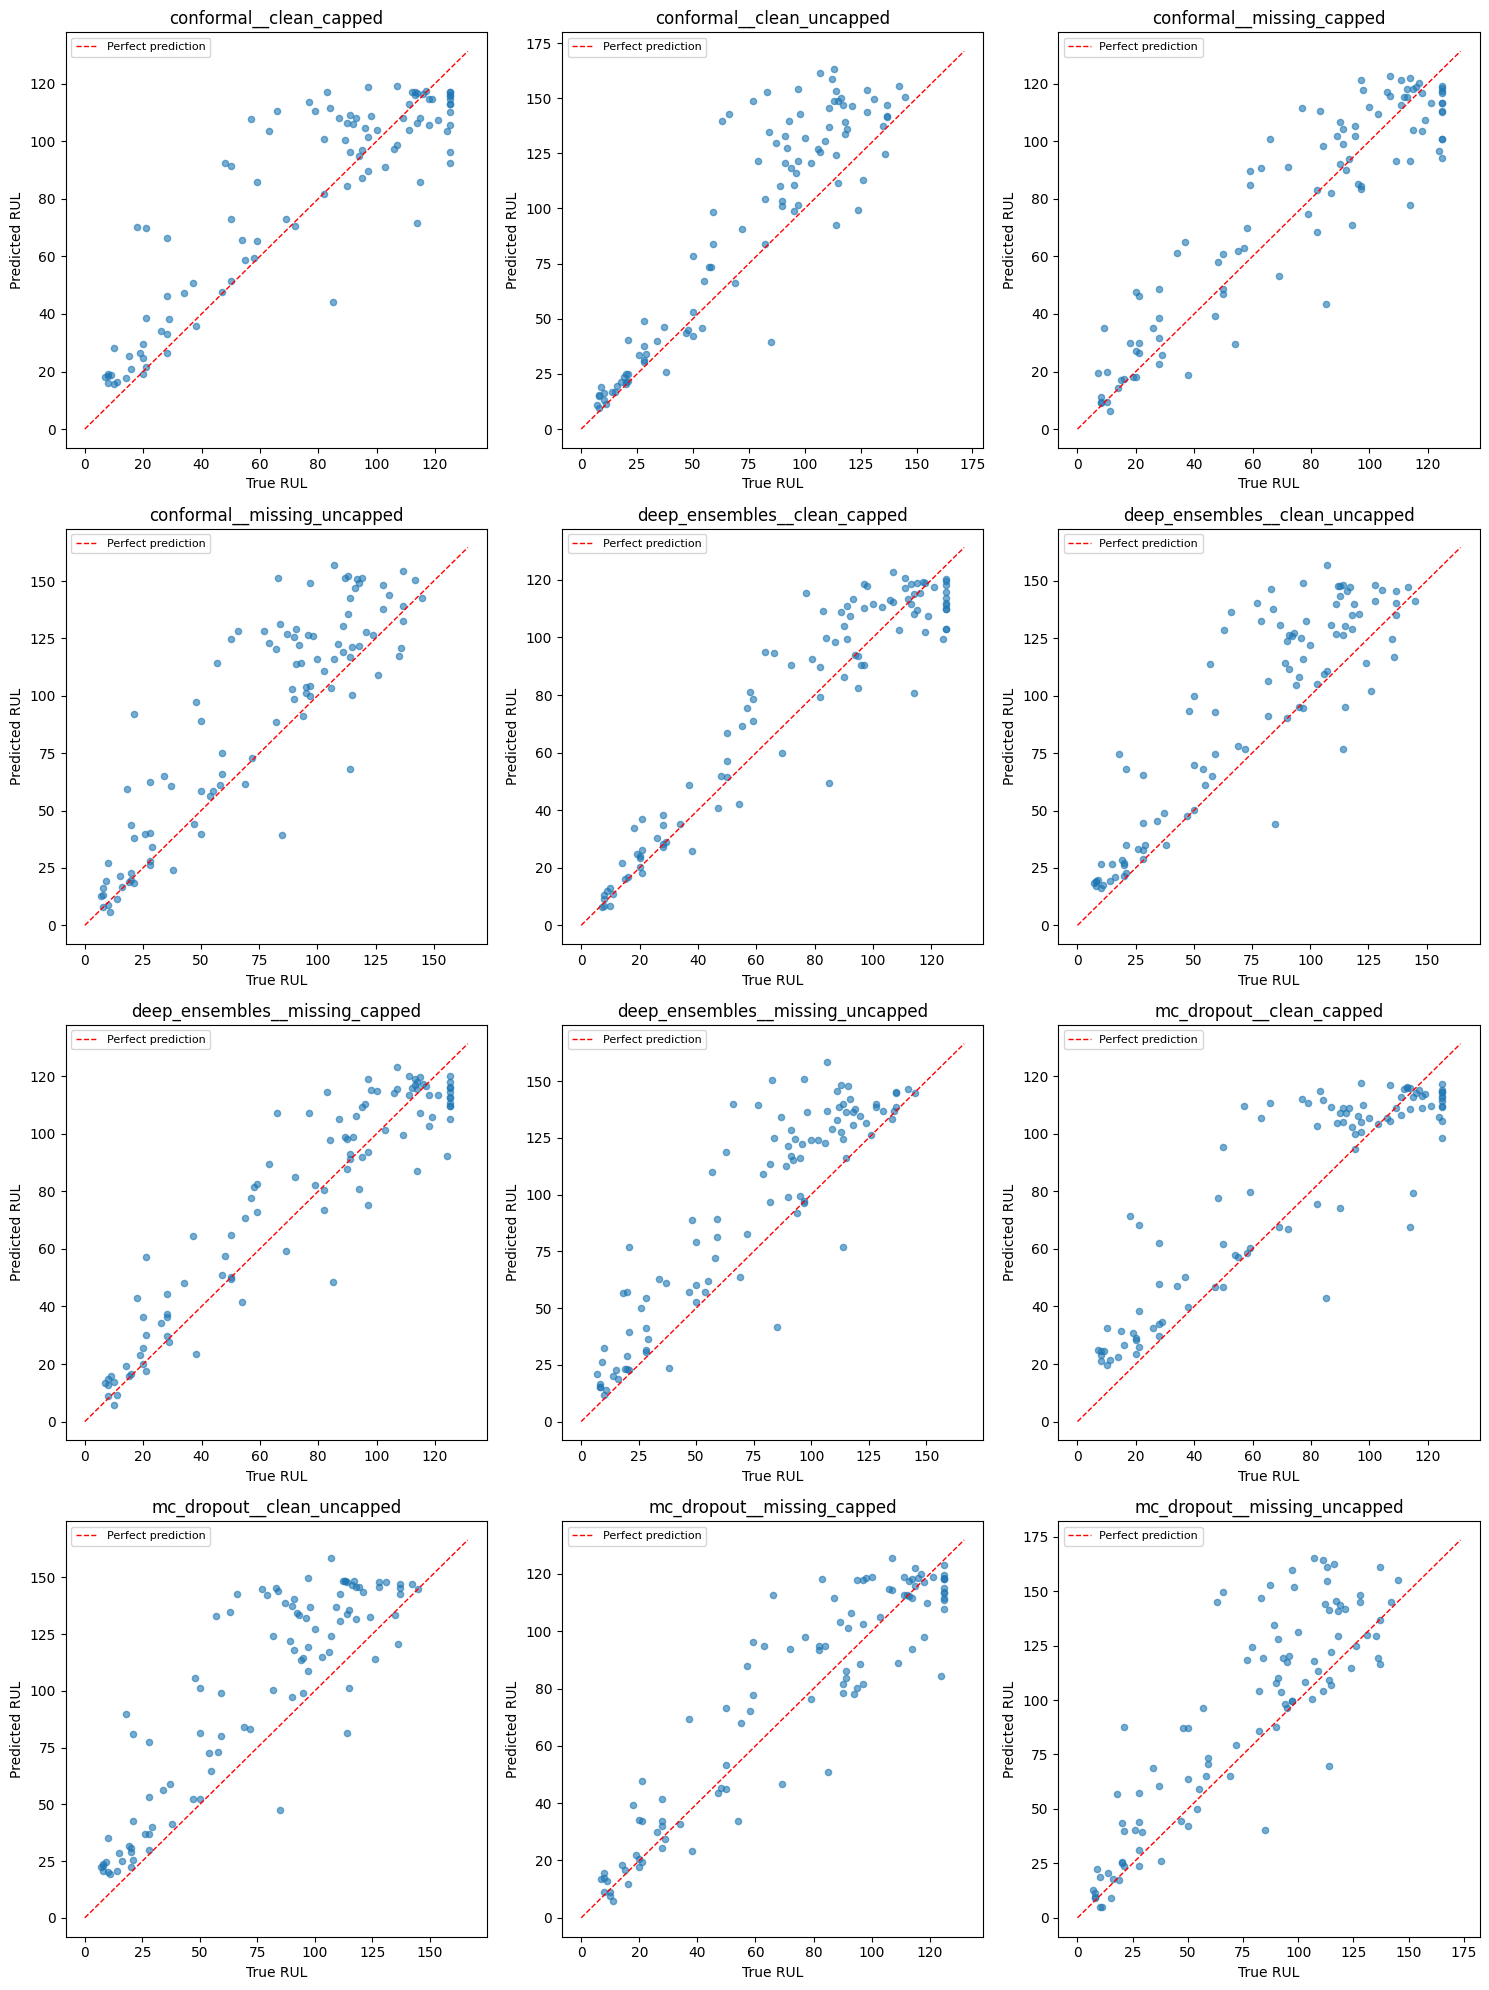

In [4]:
n = len(results)
cols = 3
rows = int(np.ceil(n / cols)) if n else 1

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, (key, df) in zip(axes, results.items()):
    ax.scatter(df["Actual_RUL"], df["Predicted_RUL"], alpha=0.6, s=20)
    lims = [0, max(df["Actual_RUL"].max(), df["Predicted_RUL"].max()) * 1.05]
    ax.plot(lims, lims, "r--", linewidth=1, label="Perfect prediction")
    ax.set_xlabel("True RUL")
    ax.set_ylabel("Predicted RUL")
    ax.set_title(key)
    ax.legend(fontsize=8)

for ax in axes[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/plot_predicted_vs_true.png", dpi=150)
plt.show()


## 2. Uncertainty-band plot

Engines sorted by true RUL on the x-axis; predicted RUL as a line with a shaded band of `± Uncertainty` around it, true RUL as scatter points. A well-behaved method should have the true points fall inside the band most of the time, and the band should visibly narrow where the model is genuinely more confident.

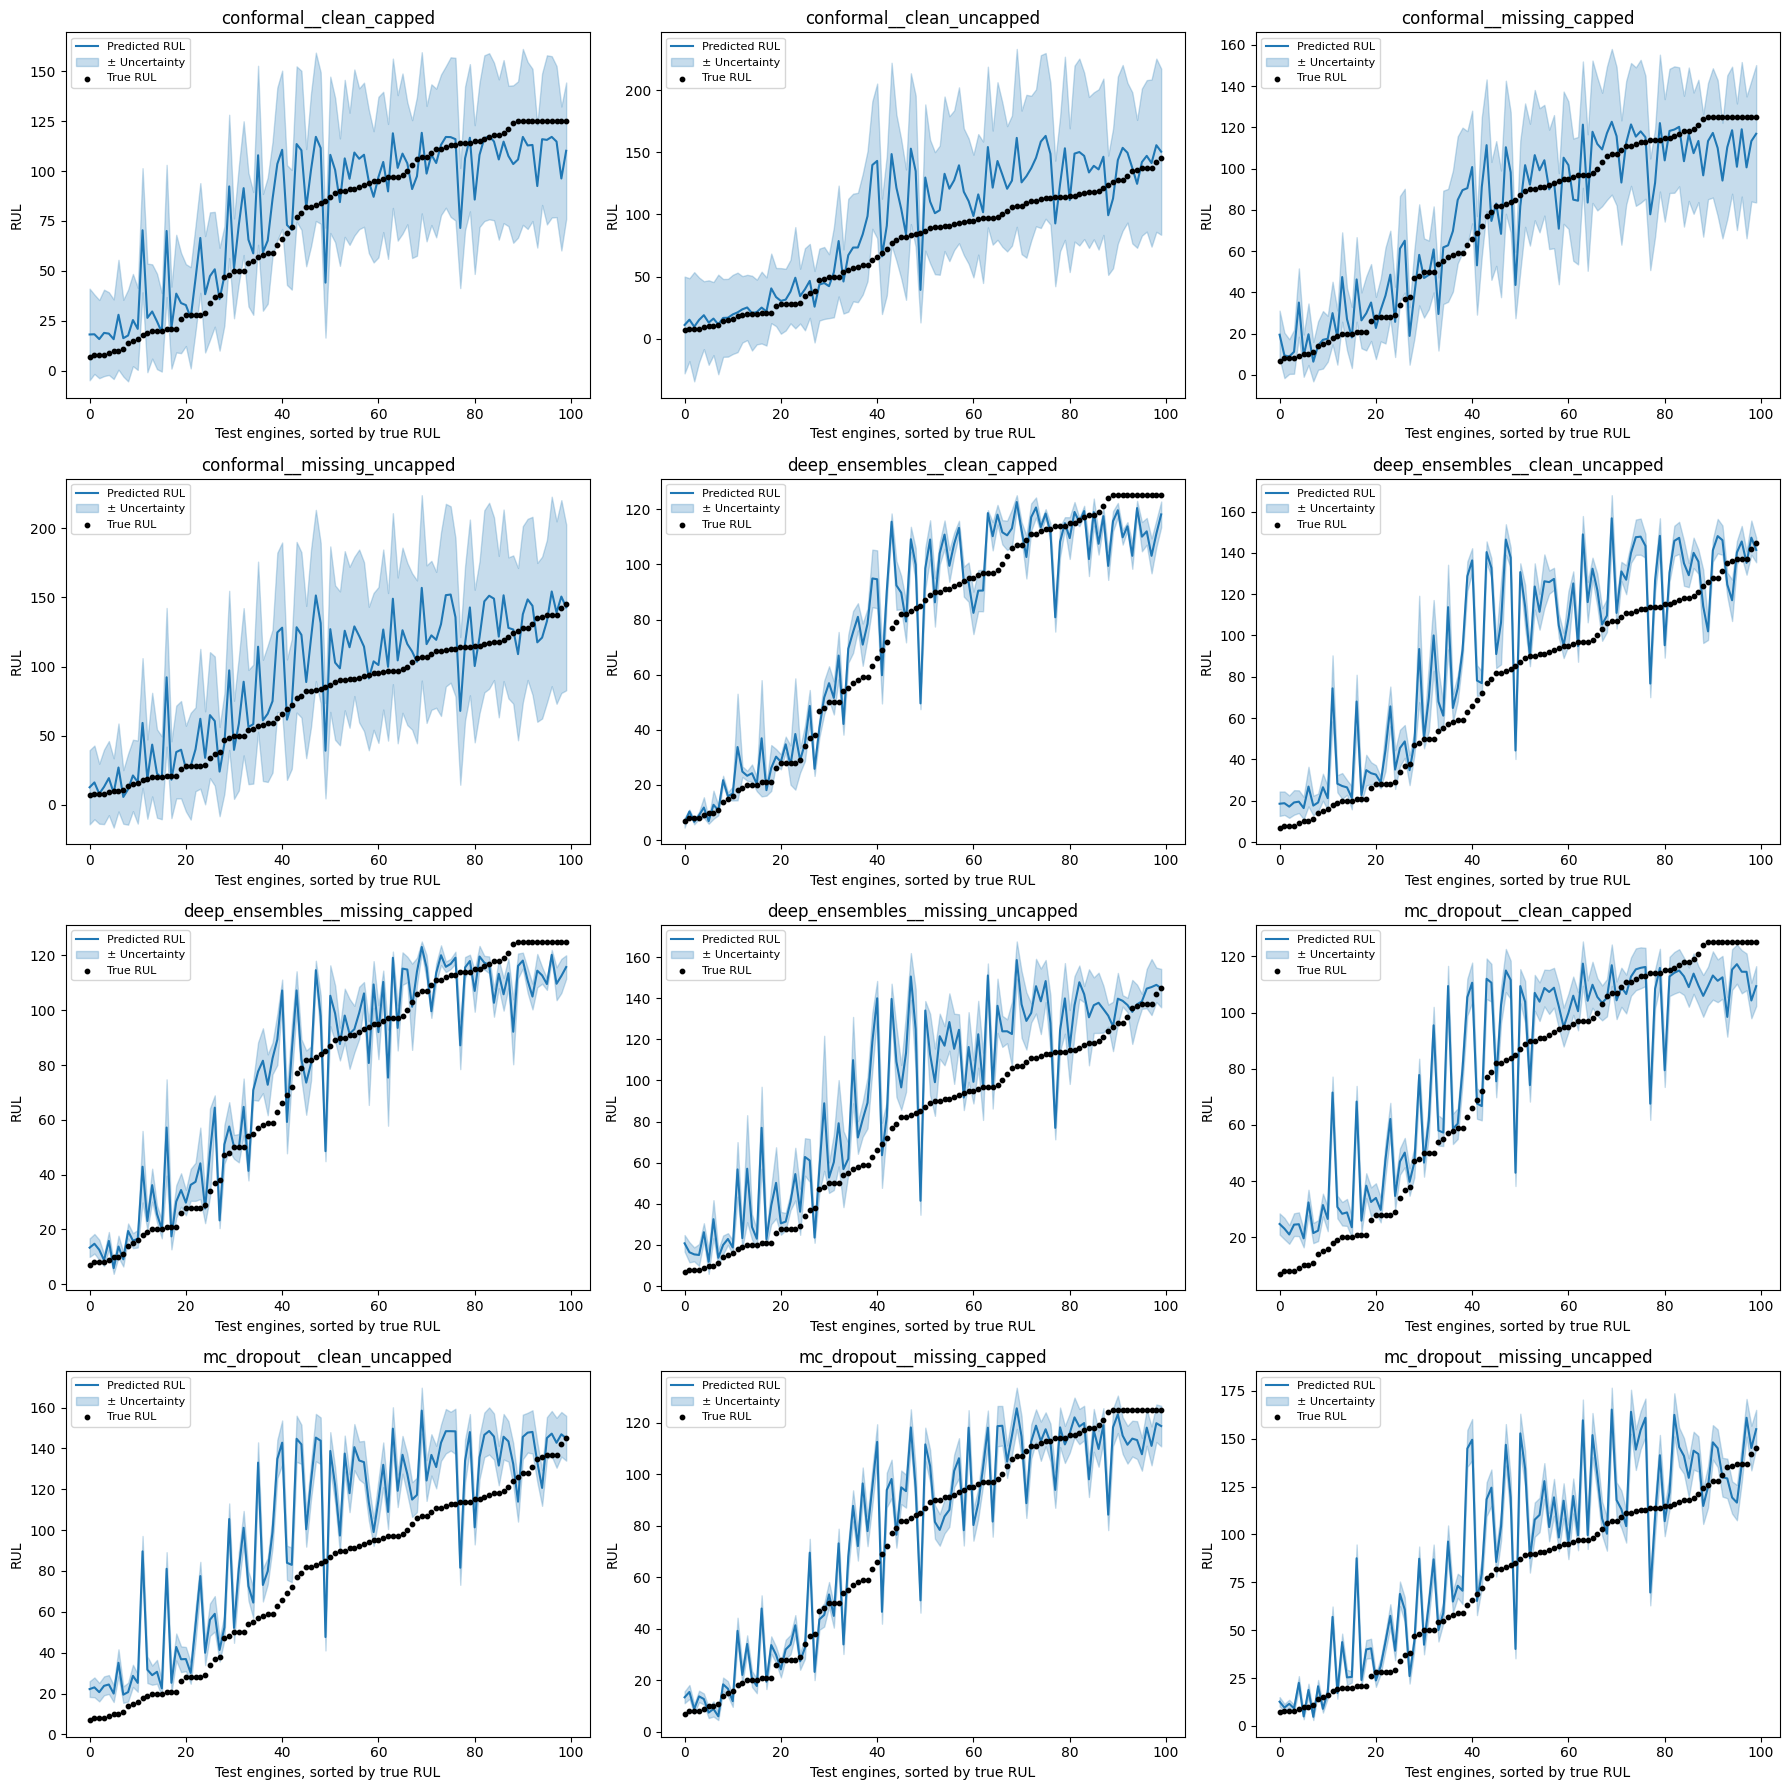

In [5]:
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.5 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, (key, df) in zip(axes, results.items()):
    d = df.sort_values("Actual_RUL").reset_index(drop=True)
    x = np.arange(len(d))

    ax.plot(x, d["Predicted_RUL"], color="C0", label="Predicted RUL")
    ax.fill_between(
        x,
        d["Predicted_RUL"] - d["Uncertainty"],
        d["Predicted_RUL"] + d["Uncertainty"],
        color="C0", alpha=0.25, label="\u00b1 Uncertainty"
    )
    ax.scatter(x, d["Actual_RUL"], color="black", s=10, label="True RUL", zorder=5)

    ax.set_xlabel("Test engines, sorted by true RUL")
    ax.set_ylabel("RUL")
    ax.set_title(key)
    ax.legend(fontsize=8)

for ax in axes[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/plot_uncertainty_bands.png", dpi=150)
plt.show()


## 3. Risk-coverage curve (the headline figure)

For each scenario (e.g. clean/capped), sort the test engines by *this method's own*
uncertainty, then sweep the acceptance threshold from 100% coverage down to 50%,
recomputing RMSE and NASA Score on whatever is still accepted at each step.

Note: this sorts directly on the test set's own uncertainty distribution to get a
smooth curve for the figure -- it's a standard way to visualize the
uncertainty-vs-error relationship, and is a different (looser) protocol than the
val-calibrated 90/80/70% thresholds already reported in your result tables. Use
this plot to show the *shape* of the relationship; keep citing the calibrated
sweep numbers from each notebook for your actual reported table.

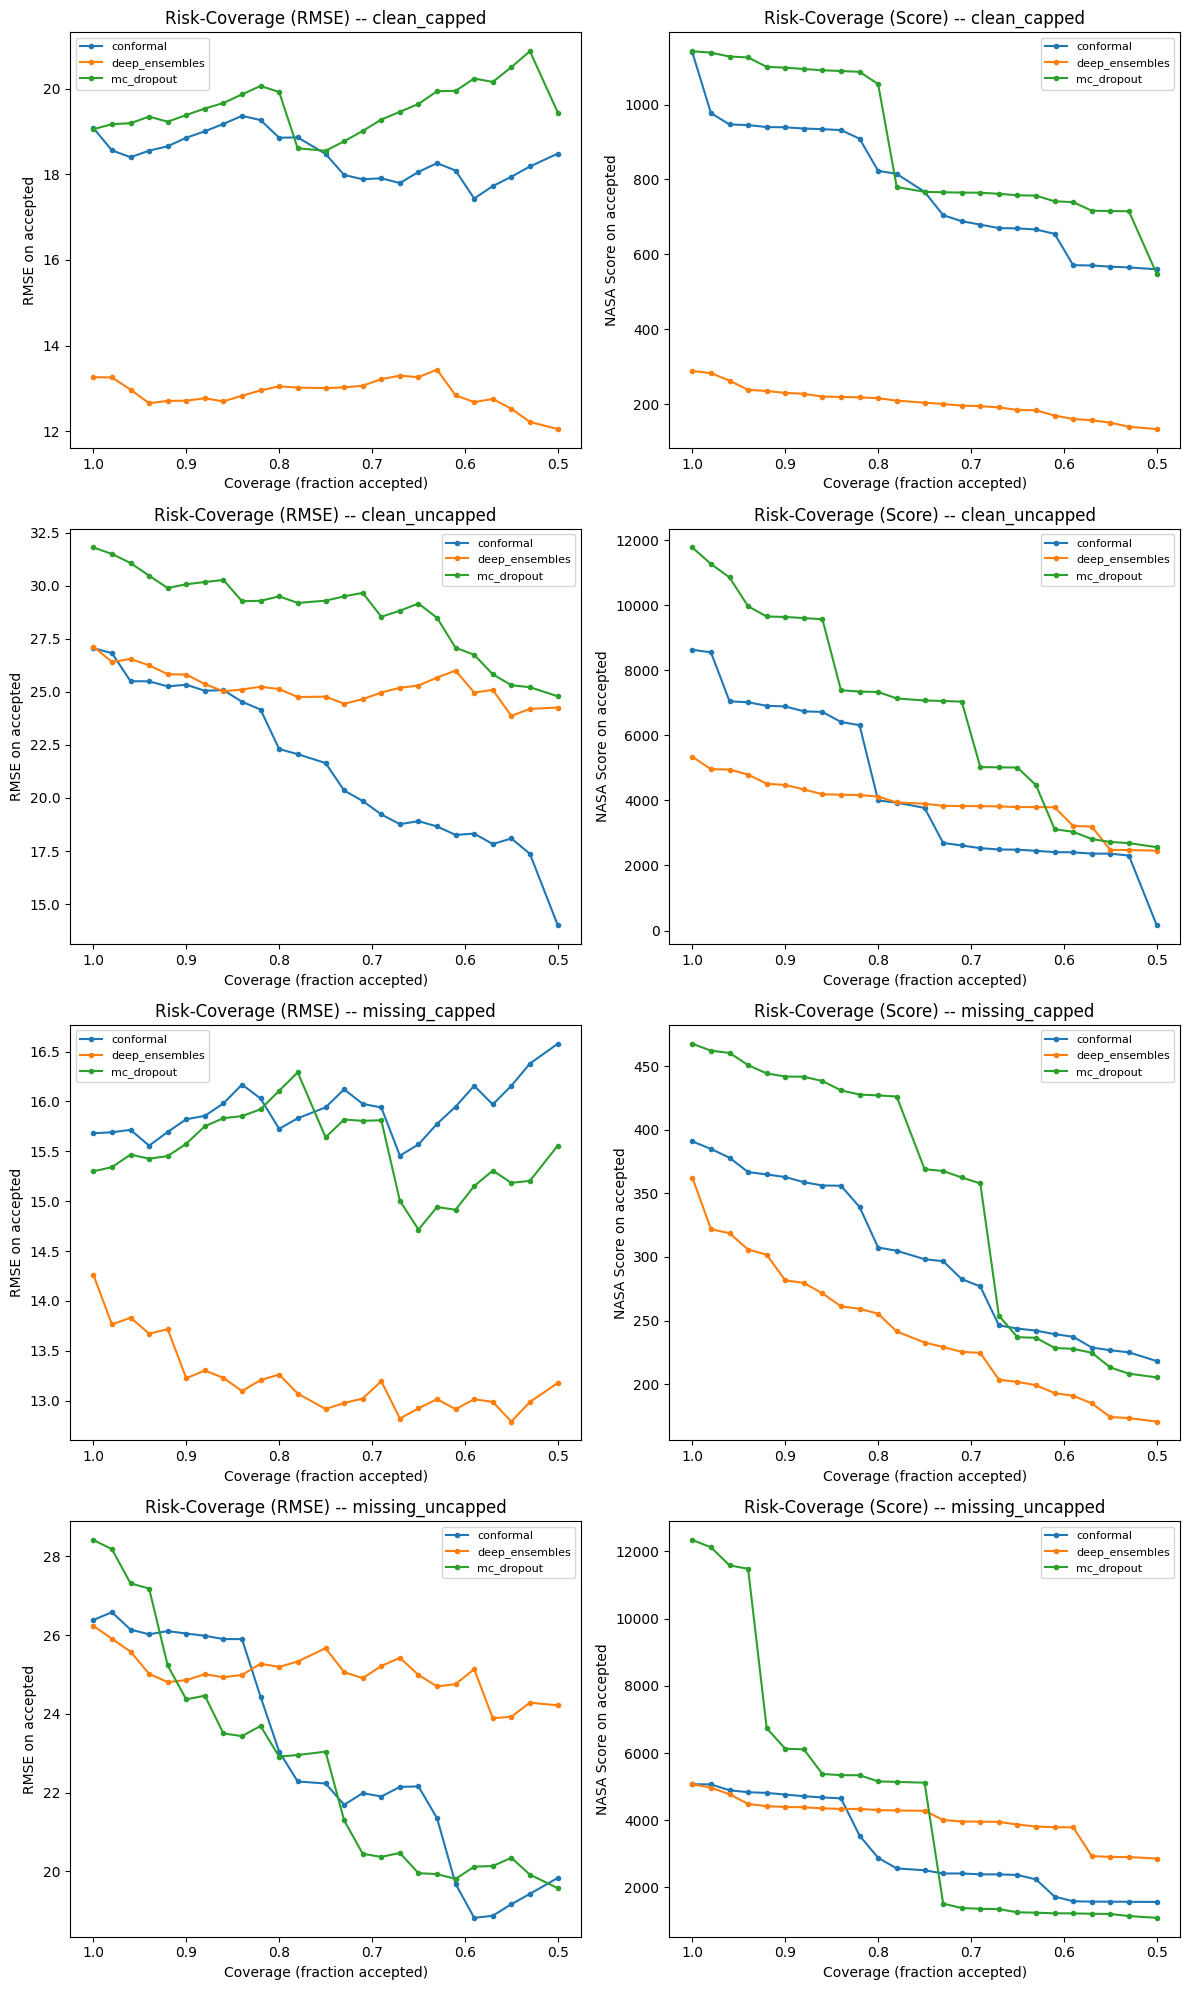

In [6]:
def risk_coverage(df, n_points=25):
    d = df.sort_values("Uncertainty").reset_index(drop=True)
    n = len(d)

    coverages, rmses, scores = [], [], []

    for frac in np.linspace(1.0, 0.5, n_points):
        k = max(2, int(np.ceil(n * frac)))
        subset = d.iloc[:k]

        rmse = np.sqrt(np.mean((subset["Actual_RUL"] - subset["Predicted_RUL"]) ** 2))
        score = nasa_score(subset["Actual_RUL"], subset["Predicted_RUL"])

        coverages.append(k / n)
        rmses.append(rmse)
        scores.append(score)

    return np.array(coverages), np.array(rmses), np.array(scores)


scenarios = sorted(set(key.split("__")[1] for key in results.keys()))

fig, axes = plt.subplots(len(scenarios), 2, figsize=(12, 5 * len(scenarios)), squeeze=False)

for row, scenario in enumerate(scenarios):
    ax_rmse, ax_score = axes[row]

    for key, df in results.items():
        if not key.endswith(scenario):
            continue
        method = key.split("__")[0]

        coverage, rmse, score = risk_coverage(df)

        ax_rmse.plot(coverage, rmse, marker="o", markersize=3, label=method)
        ax_score.plot(coverage, score, marker="o", markersize=3, label=method)

    ax_rmse.set_xlabel("Coverage (fraction accepted)")
    ax_rmse.set_ylabel("RMSE on accepted")
    ax_rmse.set_title(f"Risk-Coverage (RMSE) -- {scenario}")
    ax_rmse.invert_xaxis()
    ax_rmse.legend(fontsize=8)

    ax_score.set_xlabel("Coverage (fraction accepted)")
    ax_score.set_ylabel("NASA Score on accepted")
    ax_score.set_title(f"Risk-Coverage (Score) -- {scenario}")
    ax_score.invert_xaxis()
    ax_score.legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/plot_risk_coverage.png", dpi=150)
plt.show()


## 4. Method comparison bar chart

RMSE, Score, and MAE at 100% coverage (accepting everything), grouped by scenario, one bar cluster per method.

        Method         Scenario      RMSE       MAE        Score
     conformal     clean_capped 19.079856 13.862698  1138.974833
     conformal   clean_uncapped 27.060214 20.023986  8630.416237
     conformal   missing_capped 15.681002 12.330185   390.819618
     conformal missing_uncapped 26.382055 19.352337  5071.987647
deep_ensembles     clean_capped 13.262050 10.066379   288.482849
deep_ensembles   clean_uncapped 27.136930 20.695876  5342.013525
deep_ensembles   missing_capped 14.261761 11.013371   362.425636
deep_ensembles missing_uncapped 26.231857 20.181961  5069.828764
    mc_dropout     clean_capped 19.052245 14.073756  1142.368924
    mc_dropout   clean_uncapped 31.806547 25.513426 11776.147791
    mc_dropout   missing_capped 15.299866 11.537984   467.646716
    mc_dropout missing_uncapped 28.412118 20.579288 12341.338802


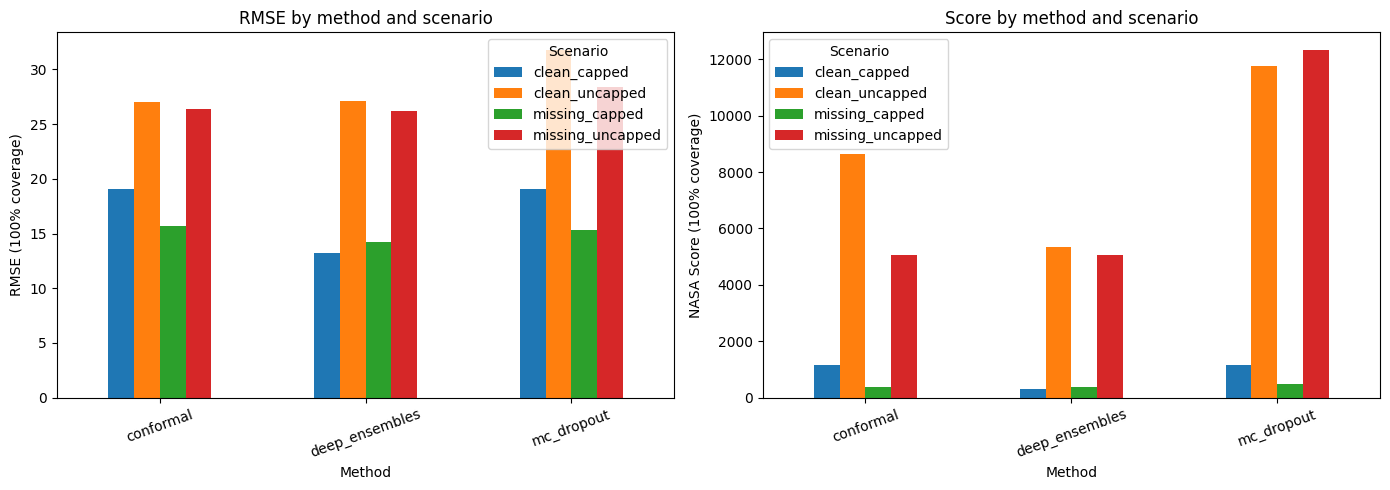


Saved results/summary_table.csv -- this is your paper table, ready to format.


In [7]:
summary_rows = []

for key, df in results.items():
    method, scenario = key.split("__")
    rmse = np.sqrt(np.mean((df["Actual_RUL"] - df["Predicted_RUL"]) ** 2))
    mae = np.mean(np.abs(df["Actual_RUL"] - df["Predicted_RUL"]))
    score = nasa_score(df["Actual_RUL"], df["Predicted_RUL"])
    summary_rows.append({"Method": method, "Scenario": scenario, "RMSE": rmse, "MAE": mae, "Score": score})

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pivot_rmse = summary_df.pivot(index="Method", columns="Scenario", values="RMSE")
pivot_rmse.plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("RMSE (100% coverage)")
axes[0].set_title("RMSE by method and scenario")
axes[0].tick_params(axis="x", rotation=20)

pivot_score = summary_df.pivot(index="Method", columns="Scenario", values="Score")
pivot_score.plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("NASA Score (100% coverage)")
axes[1].set_title("Score by method and scenario")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("results/plot_method_comparison.png", dpi=150)
plt.show()

summary_df.to_csv("results/summary_table.csv", index=False)
print("\nSaved results/summary_table.csv -- this is your paper table, ready to format.")
